# House Prices Prediction (Kaggle)

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import torch
from aif import DataModule, LinearRegression, Trainer, plot_history

## Prepare Dataset
- Load Kaggle train/test CSVs
- Standardize numeric features, one-hot encode categorical features
- Log-transform the `SalePrice` target

In [2]:
class KaggleHousePricesDataset(DataModule):
    def __init__(self, root='../data', batch_size=64, train=None, val=None):
        super().__init__(batch_size=batch_size)

        if train is None:
            train_path = f'{root}/house_prices_kaggle/train.csv'
            val_path = f'{root}/house_prices_kaggle/test.csv'

            self.raw_train = pd.read_csv(train_path)
            self.raw_val = pd.read_csv(val_path)

            self.train = None
            self.val = None
        else:
            self.train = train
            self.val = val

    def preprocess(self):
        label = 'SalePrice'
        features = pd.concat((
            self.raw_train.drop(columns=['Id', label]),
            self.raw_val.drop(columns=['Id'])
        ))

        numeric_features = features.select_dtypes('number').columns
        features[numeric_features] = features[numeric_features].apply(
            lambda x: (x - x.mean()) / (x.std())
        )
        features[numeric_features] = features[numeric_features].fillna(0)

        features = pd.get_dummies(features, dummy_na=True)

        self.train = features[:self.raw_train.shape[0]].copy()
        self.train[label] = self.raw_train[label]
        self.val = features[self.raw_train.shape[0]:].copy()

    def get_dataloader(self, train):
        label = 'SalePrice'
        data = self.train if train else self.val

        if label not in data:
            return

        get_tensor = lambda x: torch.tensor(
            x.values.astype(float),
            dtype=torch.float32
        )

        tensors = (
            get_tensor(data.drop(columns=[label])),
            torch.log(get_tensor(data[label])).reshape((-1, 1))
        )

        return self._get_tensorloader(tensors, train)

In [3]:
data = KaggleHousePricesDataset()

data.raw_train.shape, data.raw_val.shape

((1460, 81), (1459, 80))

In [4]:
data.preprocess()

data.train.shape, data.val.shape

((1460, 331), (1459, 330))

## Model

`LinearRegression` is imported from `aif` (first defined in `01_linear_regression.ipynb`). It uses `nn.LazyLinear`, so the number of inputs is inferred from the first batch, and `bias_init` starts the bias at the mean log price.

## Training

In [6]:
log_prices = np.log(data.train.iloc[:, -1].to_numpy())

model = LinearRegression(lr=0.01, bias_init=log_prices.mean())

tensor([12.0241])

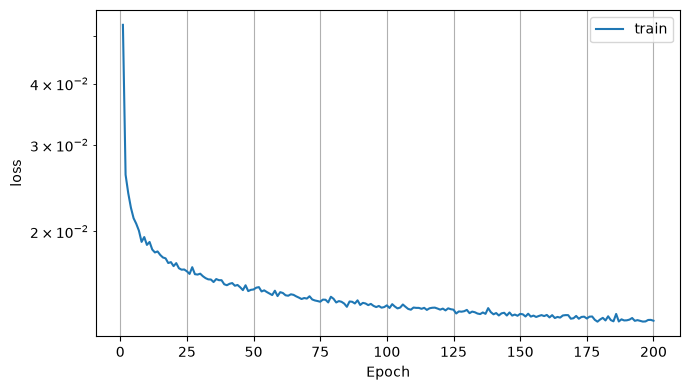

Epoch 200/200 | train_loss: 0.013152

In [7]:
trainer = Trainer(max_epochs=200, yscale='log')

trainer.fit(model, data)

## Inference
- Predict prices for the test set (back from log space)

In [8]:
with torch.no_grad():
    preds = torch.exp(model(torch.tensor(data.val.values.astype(float), dtype=torch.float32))).squeeze(1)

## Submission

In [9]:
submission_df = pd.DataFrame({
    'Id': data.raw_val.Id,
    'SalePrice': preds.detach().numpy()
})

display(submission_df)

,Id,SalePrice
0,1461,113856.320312
1,1462,150358.296875
2,1463,169810.843750
3,1464,193146.937500
4,1465,196905.703125
...,...,...
1454,2915,84252.195312
1455,2916,83315.187500
1456,2917,158388.781250
1457,2918,110314.398438


In [10]:
# submissions = Path('../submissions')
# submissions.mkdir(exist_ok=True)
# submission_df.to_csv(submissions / 'submission_log_space_200_epochs_mean_bias.csv', index=False)

## k-Fold Cross Validation

In [11]:
def k_fold_data(data, k):
    rets = []
    fold_size = data.train.shape[0] // k
    for j in range(k):
        idx = range(j * fold_size, (j+1) * fold_size)
        rets.append(KaggleHousePricesDataset(
            batch_size=data.batch_size, 
            train=data.train.drop(index=idx),
            val=data.train.loc[idx]
        ))
    
    return rets

def report_folds(histories):
    # final-epoch metrics per fold, as log-RMSE (the Kaggle metric)
    summary = pd.DataFrame(
        {
            'train log-RMSE': [h['train_loss'][-1] ** 0.5 for h in histories],
            'val log-RMSE': [h['val_loss'][-1] ** 0.5 for h in histories],
        },
        index=pd.RangeIndex(1, len(histories) + 1, name='fold'),
    )
    display(summary.round(4))

    val_loss = np.mean([h['val_loss'][-1] for h in histories])
    val_rmse = summary['val log-RMSE']
    print(
        f'CV error: val MSE {val_loss:.4f} | log-RMSE {val_loss ** 0.5:.4f} '
        f'| per-fold log-RMSE {val_rmse.mean():.4f} ± {val_rmse.std():.4f}'
    )

    # keys '<fold>_<metric>' give one panel per metric with one line per fold
    all_folds = {
        f'fold{i + 1}_{key}': values
        for i, h in enumerate(histories)
        for key, values in h.items()
    }
    plot_history(all_folds, figsize=(10, 4), yscale='log', title='All folds')
    plt.show()

def k_fold(trainer, data, k, lr):
    models, histories = [], []
    for i, data_fold in enumerate(k_fold_data(data, k)):
        log_prices = np.log(data_fold.train.iloc[:, -1].to_numpy())
        model = LinearRegression(lr=lr, bias_init=log_prices.mean())

        trainer.title = f'Fold {i + 1}/{k}'
        trainer.fit(model, data_fold)
        models.append(model)
        histories.append(trainer.history)

    report_folds(histories)
    
    return models, histories

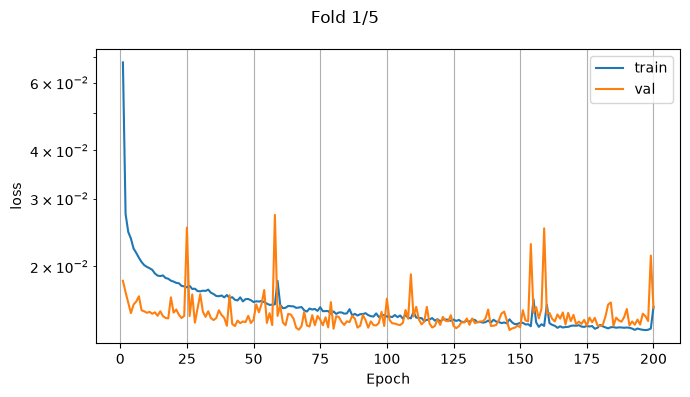

Fold 1/5 | Epoch  20/200 | train_loss: 0.018264 | val_loss: 0.015171
Fold 1/5 | Epoch  40/200 | train_loss: 0.016852 | val_loss: 0.014023
Fold 1/5 | Epoch  60/200 | train_loss: 0.015889 | val_loss: 0.015838
Fold 1/5 | Epoch  80/200 | train_loss: 0.015279 | val_loss: 0.013779
Fold 1/5 | Epoch 100/200 | train_loss: 0.014811 | val_loss: 0.016495
Fold 1/5 | Epoch 120/200 | train_loss: 0.014397 | val_loss: 0.014098
Fold 1/5 | Epoch 140/200 | train_loss: 0.014539 | val_loss: 0.014024
Fold 1/5 | Epoch 160/200 | train_loss: 0.015909 | val_loss: 0.015084
Fold 1/5 | Epoch 180/200 | train_loss: 0.014094 | val_loss: 0.013996
Fold 1/5 | Epoch 200/200 | train_loss: 0.015685 | val_loss: 0.015595


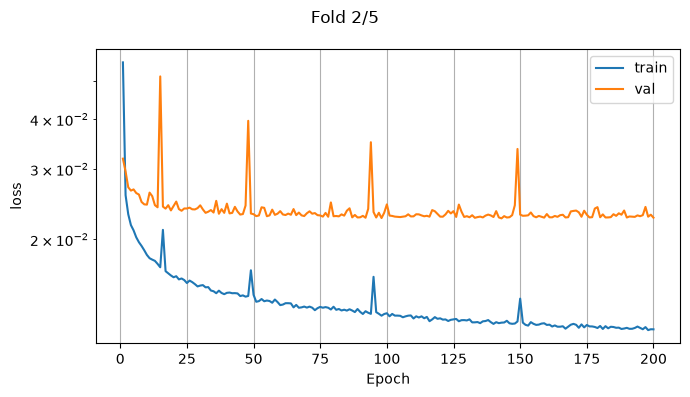

Fold 2/5 | Epoch  20/200 | train_loss: 0.016079 | val_loss: 0.024248
Fold 2/5 | Epoch  40/200 | train_loss: 0.014697 | val_loss: 0.024584
Fold 2/5 | Epoch  60/200 | train_loss: 0.013692 | val_loss: 0.023541
Fold 2/5 | Epoch  80/200 | train_loss: 0.013564 | val_loss: 0.022864
Fold 2/5 | Epoch 100/200 | train_loss: 0.013066 | val_loss: 0.024478
Fold 2/5 | Epoch 120/200 | train_loss: 0.012687 | val_loss: 0.022807
Fold 2/5 | Epoch 140/200 | train_loss: 0.012287 | val_loss: 0.022760
Fold 2/5 | Epoch 160/200 | train_loss: 0.012214 | val_loss: 0.023151
Fold 2/5 | Epoch 180/200 | train_loss: 0.012139 | val_loss: 0.022728
Fold 2/5 | Epoch 200/200 | train_loss: 0.011907 | val_loss: 0.022672


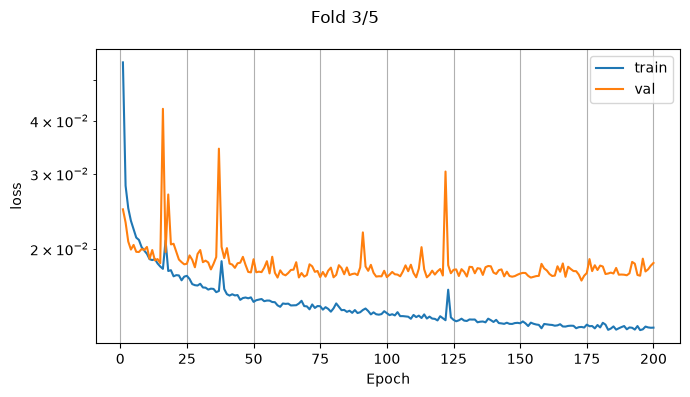

Fold 3/5 | Epoch  20/200 | train_loss: 0.017227 | val_loss: 0.020545
Fold 3/5 | Epoch  40/200 | train_loss: 0.015640 | val_loss: 0.020070
Fold 3/5 | Epoch  60/200 | train_loss: 0.014605 | val_loss: 0.017793
Fold 3/5 | Epoch  80/200 | train_loss: 0.014484 | val_loss: 0.017135
Fold 3/5 | Epoch 100/200 | train_loss: 0.014106 | val_loss: 0.017151
Fold 3/5 | Epoch 120/200 | train_loss: 0.013879 | val_loss: 0.017922
Fold 3/5 | Epoch 140/200 | train_loss: 0.013455 | val_loss: 0.017581
Fold 3/5 | Epoch 160/200 | train_loss: 0.013281 | val_loss: 0.017782
Fold 3/5 | Epoch 180/200 | train_loss: 0.013061 | val_loss: 0.018258
Fold 3/5 | Epoch 200/200 | train_loss: 0.013047 | val_loss: 0.018519


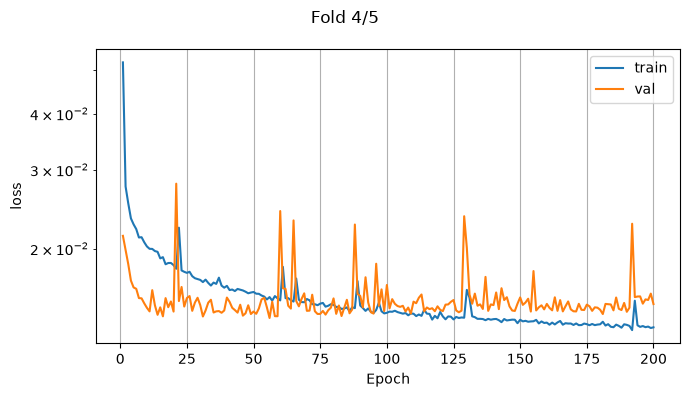

Fold 4/5 | Epoch  20/200 | train_loss: 0.018367 | val_loss: 0.014468
Fold 4/5 | Epoch  40/200 | train_loss: 0.016511 | val_loss: 0.015547
Fold 4/5 | Epoch  60/200 | train_loss: 0.015322 | val_loss: 0.024254
Fold 4/5 | Epoch  80/200 | train_loss: 0.014973 | val_loss: 0.015479
Fold 4/5 | Epoch 100/200 | train_loss: 0.014376 | val_loss: 0.016585
Fold 4/5 | Epoch 120/200 | train_loss: 0.014436 | val_loss: 0.014596
Fold 4/5 | Epoch 140/200 | train_loss: 0.013914 | val_loss: 0.014958
Fold 4/5 | Epoch 160/200 | train_loss: 0.013668 | val_loss: 0.015048
Fold 4/5 | Epoch 180/200 | train_loss: 0.013551 | val_loss: 0.014603
Fold 4/5 | Epoch 200/200 | train_loss: 0.013342 | val_loss: 0.015038


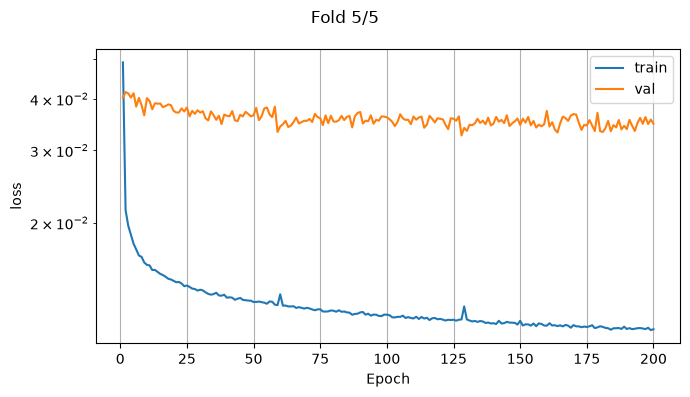

Fold 5/5 | Epoch  20/200 | train_loss: 0.014461 | val_loss: 0.037415
Fold 5/5 | Epoch  40/200 | train_loss: 0.013155 | val_loss: 0.036385
Fold 5/5 | Epoch  60/200 | train_loss: 0.013409 | val_loss: 0.034287
Fold 5/5 | Epoch  80/200 | train_loss: 0.012229 | val_loss: 0.035240
Fold 5/5 | Epoch 100/200 | train_loss: 0.011963 | val_loss: 0.036085
Fold 5/5 | Epoch 120/200 | train_loss: 0.011684 | val_loss: 0.035775
Fold 5/5 | Epoch 140/200 | train_loss: 0.011403 | val_loss: 0.034840
Fold 5/5 | Epoch 160/200 | train_loss: 0.011247 | val_loss: 0.037403
Fold 5/5 | Epoch 180/200 | train_loss: 0.011212 | val_loss: 0.033394
Fold 5/5 | Epoch 200/200 | train_loss: 0.011028 | val_loss: 0.034831


,train log-RMSE,val log-RMSE
fold,,
1,0.1252,0.1249
2,0.1091,0.1506
3,0.1142,0.1361
4,0.1155,0.1226
5,0.1050,0.1866


CV error: val MSE 0.0213 | log-RMSE 0.1461 | per-fold log-RMSE 0.1442 ± 0.0262


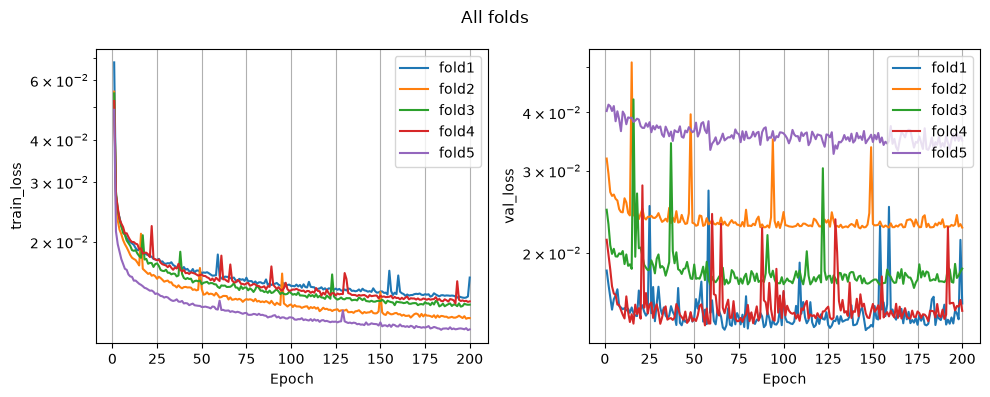

In [13]:
trainer = Trainer(max_epochs=200, yscale='log', log_every=20)
models, histories = k_fold(trainer, data, k=5, lr=0.01)

In [14]:
with torch.no_grad():
    log_preds = [
        model(torch.tensor(data.val.values.astype(float), dtype=torch.float32))
        for model in models
    ]

    # average in log space (geometric mean of prices) to match the log-RMSE metric
    ensemble_preds = torch.exp(torch.cat(log_preds, dim=1).mean(dim=1))

In [15]:
submission_df = pd.DataFrame({
    'Id': data.raw_val.Id,
    'SalePrice': ensemble_preds.numpy()
})

display(submission_df)

,Id,SalePrice
0,1461,113303.898438
1,1462,144313.812500
2,1463,170087.187500
3,1464,193216.750000
4,1465,194791.234375
...,...,...
1454,2915,85055.476562
1455,2916,84097.179688
1456,2917,156975.687500
1457,2918,111102.859375


In [16]:
# submissions = Path('../submissions')
# submissions.mkdir(exist_ok=True)
# submission_df.to_csv(submissions / 'submission_log_space_200_epochs_mean_bias_kfold.csv', index=False)